# pyQSOfit decomposition

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from pyqsofit.PyQSOFit import QSOFit

data_dir = data_dir = (Path.home()/"Cal_Poly"/"BLR_Group"/"caramel-student-package"/"caramel-master"/"code"/"Data"/"mcg0811_MDM_2014")
spectra_files = sorted(data_dir.glob("average_post5_*.txt"))

print("Data folder exists:", data_dir.is_dir())
print("Number of spectra:", len(spectra_files))
print("First file:", spectra_files[0] if spectra_files else "None found")

Data folder exists: True
Number of spectra: 82
First file: /Users/emlilio/Cal_Poly/BLR_Group/caramel-student-package/caramel-master/code/Data/mcg0811_MDM_2014/average_post5_140103.txt


File:  average_post5_140223.txt
Shape:  (1027, 3)
First three rows:
  [[4.30625e+03 4.21220e-15 6.19770e-17]
 [4.30750e+03 4.26270e-15 6.25280e-17]
 [4.30875e+03 4.28960e-15 6.28300e-17]]


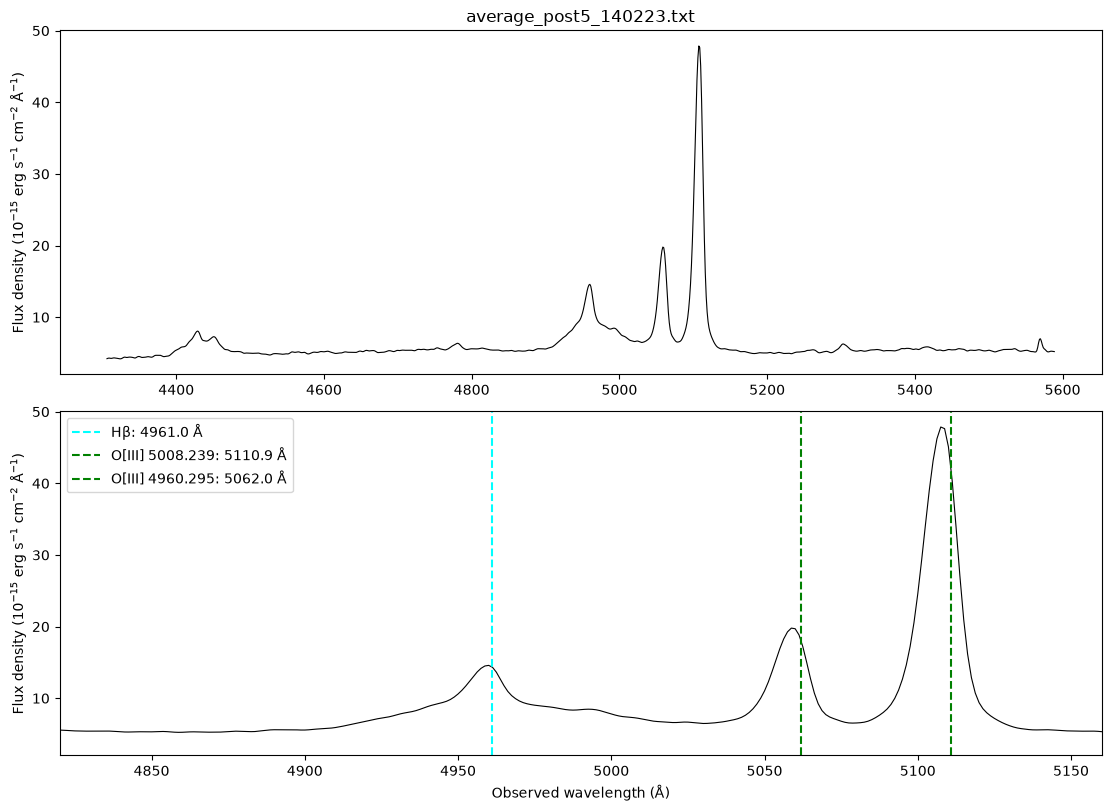

In [7]:
spectrum_file = spectra_files[len(spectra_files) // 2 ]
spectrum = np.loadtxt(spectrum_file)

wavelength = spectrum[:,0]
flux = spectrum[:, 1]
flux_error = spectrum[:,2]

print("File: ", spectrum_file.name)
print("Shape: ", spectrum.shape)
print("First three rows:\n ", spectrum[:3] )

z = 0.0205

lines = {"Hβ": 4861.33,
         "O[III] 5008.239": 5008.239,
         "O[III] 4960.295": 4960.295,}
line_colors = ["cyan", "green", "green"]

fig, axes = plt.subplots(2, 1, figsize=(11, 8), constrained_layout=True)

axes[0].plot(wavelength, flux * 1e15, color="black", linewidth=0.8)
axes[0].set_title(spectrum_file.name)
axes[0].set_ylabel(r"Flux density ($10^{-15}$ erg s$^{-1}$ cm$^{-2}$ Å$^{-1}$)")

axes[1].plot(wavelength, flux * 1e15, color="black", linewidth=0.8)
axes[1].set_xlim(4820, 5160)
axes[1].set_xlabel("Observed wavelength (Å)")
axes[1].set_ylabel(r"Flux density ($10^{-15}$ erg s$^{-1}$ cm$^{-2}$ Å$^{-1}$)")

for index, (line,wavelength) in enumerate(lines.items()):
    observed_wavelength = wavelength*(1+z)
    axes[1].axvline(
            observed_wavelength, 
            linestyle="--", 
            c=line_colors[index],
            label=f"{line}: {observed_wavelength:.1f} Å" )

axes[1].legend()
plt.show()



## This is a checkpoint to ensure that the horizontal grid for pbserved wavelengths is the same for each data file

In [8]:
all_spectra = [np.loadtxt(path) for path in spectra_files]

# Restore wavelength as the full array from the first spectrum
wavelength = all_spectra[0][:, 0].copy()

different_files = [
    path.name
    for path, spectrum_data in zip(spectra_files, all_spectra)
    if not np.array_equal(spectrum_data[:, 0], wavelength)
]

print("Files with a different grid:", different_files)
print("First three wavelengths:", wavelength[:3])

if not different_files:
    all_flux = np.stack([spectrum_data[:, 1] for spectrum_data in all_spectra])
    median_flux = np.median(all_flux, axis=0)
    print("Median spectrum ready:", median_flux.shape)

Files with a different grid: []
First three wavelengths: [4306.25 4307.5  4308.75]
Median spectrum ready: (1027,)


# Predicted Lines

In [9]:
oiii_lines = {
    "[O III] 4959": (4958.91, 5045, 5075),
    "[O III] 5007": (5006.84, 5095, 5120),
}

for name, (rest_wavelength, left, right) in oiii_lines.items():
    region = (wavelength >= left) & (wavelength <= right)

    measured_peak = wavelength[region][np.argmax(median_flux[region])]
    predicted_position = rest_wavelength * (1 + z)

    print(
        f"{name}: predicted = {predicted_position:.2f} Å, "
        f"peak = {measured_peak:.2f} Å, "
        f"offset = {measured_peak - predicted_position:+.2f} Å"
    )

[O III] 4959: predicted = 5060.57 Å, peak = 5058.75 Å, offset = -1.82 Å
[O III] 5007: predicted = 5109.48 Å, peak = 5107.50 Å, offset = -1.98 Å


# Starting PyQSO

In [10]:
from astropy.io import fits
from urllib.request import urlretrieve

parameter_file = Path.cwd() / "qsopar.fits"

if not parameter_file.exists():
    url = "https://raw.githubusercontent.com/legolason/PyQSOFit/master/qsopar.fits"
    urlretrieve(url, parameter_file)

print("Parameter file:", parameter_file)

with fits.open(parameter_file) as hdul:
    hdul.info()
    for index, hdu in enumerate(hdul):
        if hasattr(hdu, "columns"):
            print(f"\nExtension {index} columns:", hdu.columns.names)



Parameter file: /Users/emlilio/Cal_Poly/BLR_Group/caramel-student-package/caramel-master/code/Data/qsopar.fits
Filename: /Users/emlilio/Cal_Poly/BLR_Group/caramel-student-package/caramel-master/code/Data/qsopar.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       5   ()      
  1  LINE_PRIORS    1 BinTableHDU     61   18R x 18C   [E, 20A, E, E, 20A, J, E, E, E, E, E, E, E, J, J, J, E, J]   
  2  CONTI_WINDOWS    1 BinTableHDU     13   20R x 2C   [E, E]   
  3  CONTI_PRIORS    1 BinTableHDU     23   14R x 5C   [20A, E, E, E, J]   
  4  MEASURE_INFO    1 BinTableHDU     17   1R x 2C   [5E, 2E]   

Extension 1 columns: ['lambda', 'compname', 'minwav', 'maxwav', 'linename', 'ngauss', 'inisca', 'minsca', 'maxsca', 'inisig', 'minsig', 'maxsig', 'voff', 'vindex', 'windex', 'findex', 'fvalue', 'vary']

Extension 2 columns: ['min', 'max']

Extension 3 columns: ['parname', 'initial', 'min', 'max', 'vary']

Extension 4 columns: ['cont_loc', 'Fe_

# PyQSO info

In [11]:
from astropy.table import Table

line_priors = Table.read(parameter_file, hdu="LINE_PRIORS")

relevant = [
    ("hb" in str(comp).lower()) or ("oiii" in str(line).lower())
    for comp, line in zip(line_priors["compname"], line_priors["linename"])
]

columns = [
    "lambda", "compname", "linename", "ngauss",
    "minsig", "maxsig", "voff",
    "vindex", "windex", "findex", "vary"
]

print(line_priors[relevant][columns])

 lambda compname  linename ngauss  minsig  maxsig voff vindex windex findex vary
------- -------- --------- ------ ------- ------- ---- ------ ------ ------ ----
4862.68       Hb     Hb_br      2   0.004    0.05 0.01      0      0      0    1
4862.68       Hb     Hb_na      1 0.00023 0.00169 0.01      1      1      0    1
 4960.3       Hb OIII4959c      1 0.00023 0.00169 0.01      1      1      0    1
5008.24       Hb OIII5007c      1 0.00023 0.00169 0.01      1      1      0    1
 4960.3       Hb OIII4959w      1 0.00023   0.004 0.01      2      2      0    1
5008.24       Hb OIII5007w      1 0.00023   0.004 0.01      2      2      0    1


# Fitting

Fitting: average_post5_140223.txt
Typical scaled flux: 5.387600000000001e-15


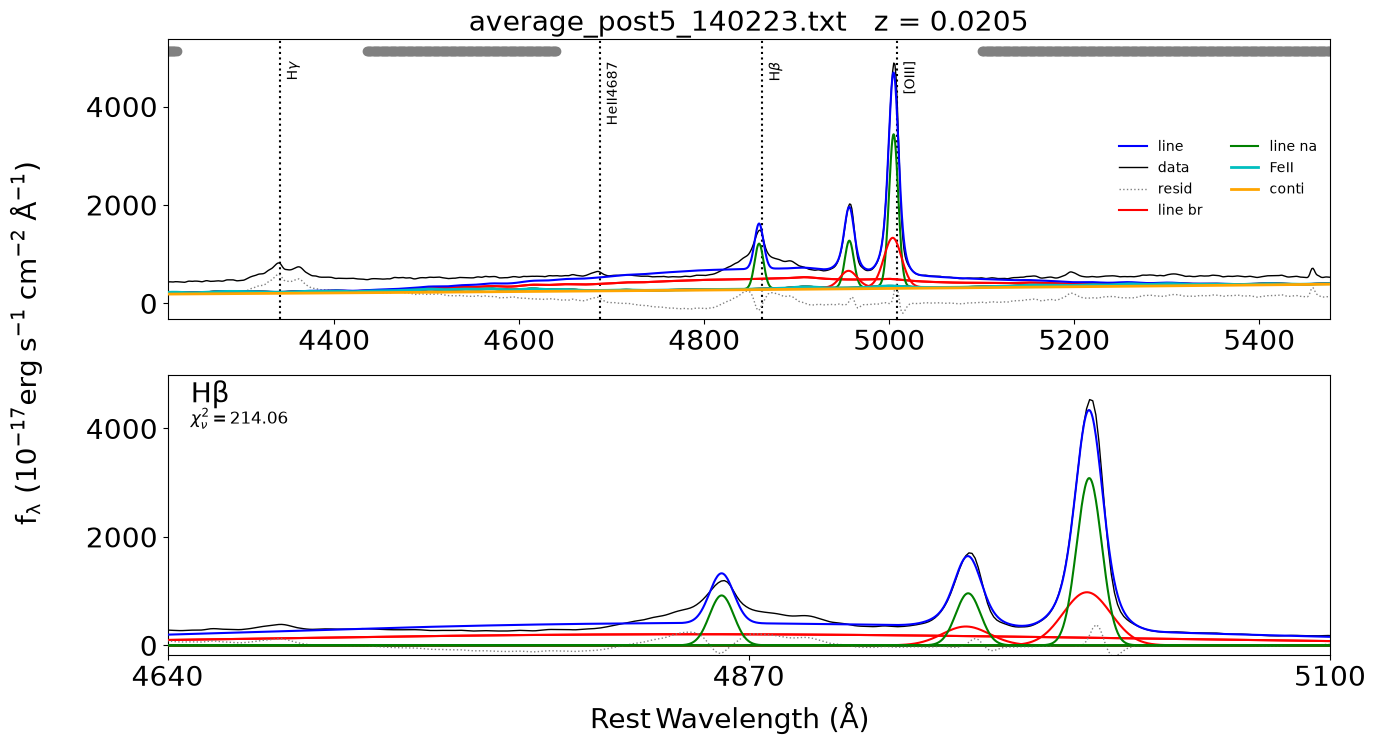

In [12]:
print("Fitting:", spectrum_file.name)
print("Typical scaled flux:", np.median(flux))

q = QSOFit(
    wavelength,
    flux*1e17,
    flux_error*1e17,
    z,
    path=str(parameter_file.parent),)

q.Fit(
    name = spectrum_file.name,
    param_file_name=parameter_file.name,
    nsmooth=1,
    reject_badpix=False,
    deredden=False,
    decompose_host=False,
    Fe_uv_op=True,
    poly=False,
    BC=False,
    linefit=True,
    MC=False,
    MCMC=False,
    save_result=False,
    plot_fig=True,
    save_fig=False,)

## reduced chi squared

In [44]:
results = dict(zip(q.line_result_name, q.line_result))
print(results["1_line_red_chi2"])

214.0572023388117


# Plotting all epochs to check for outliers

82


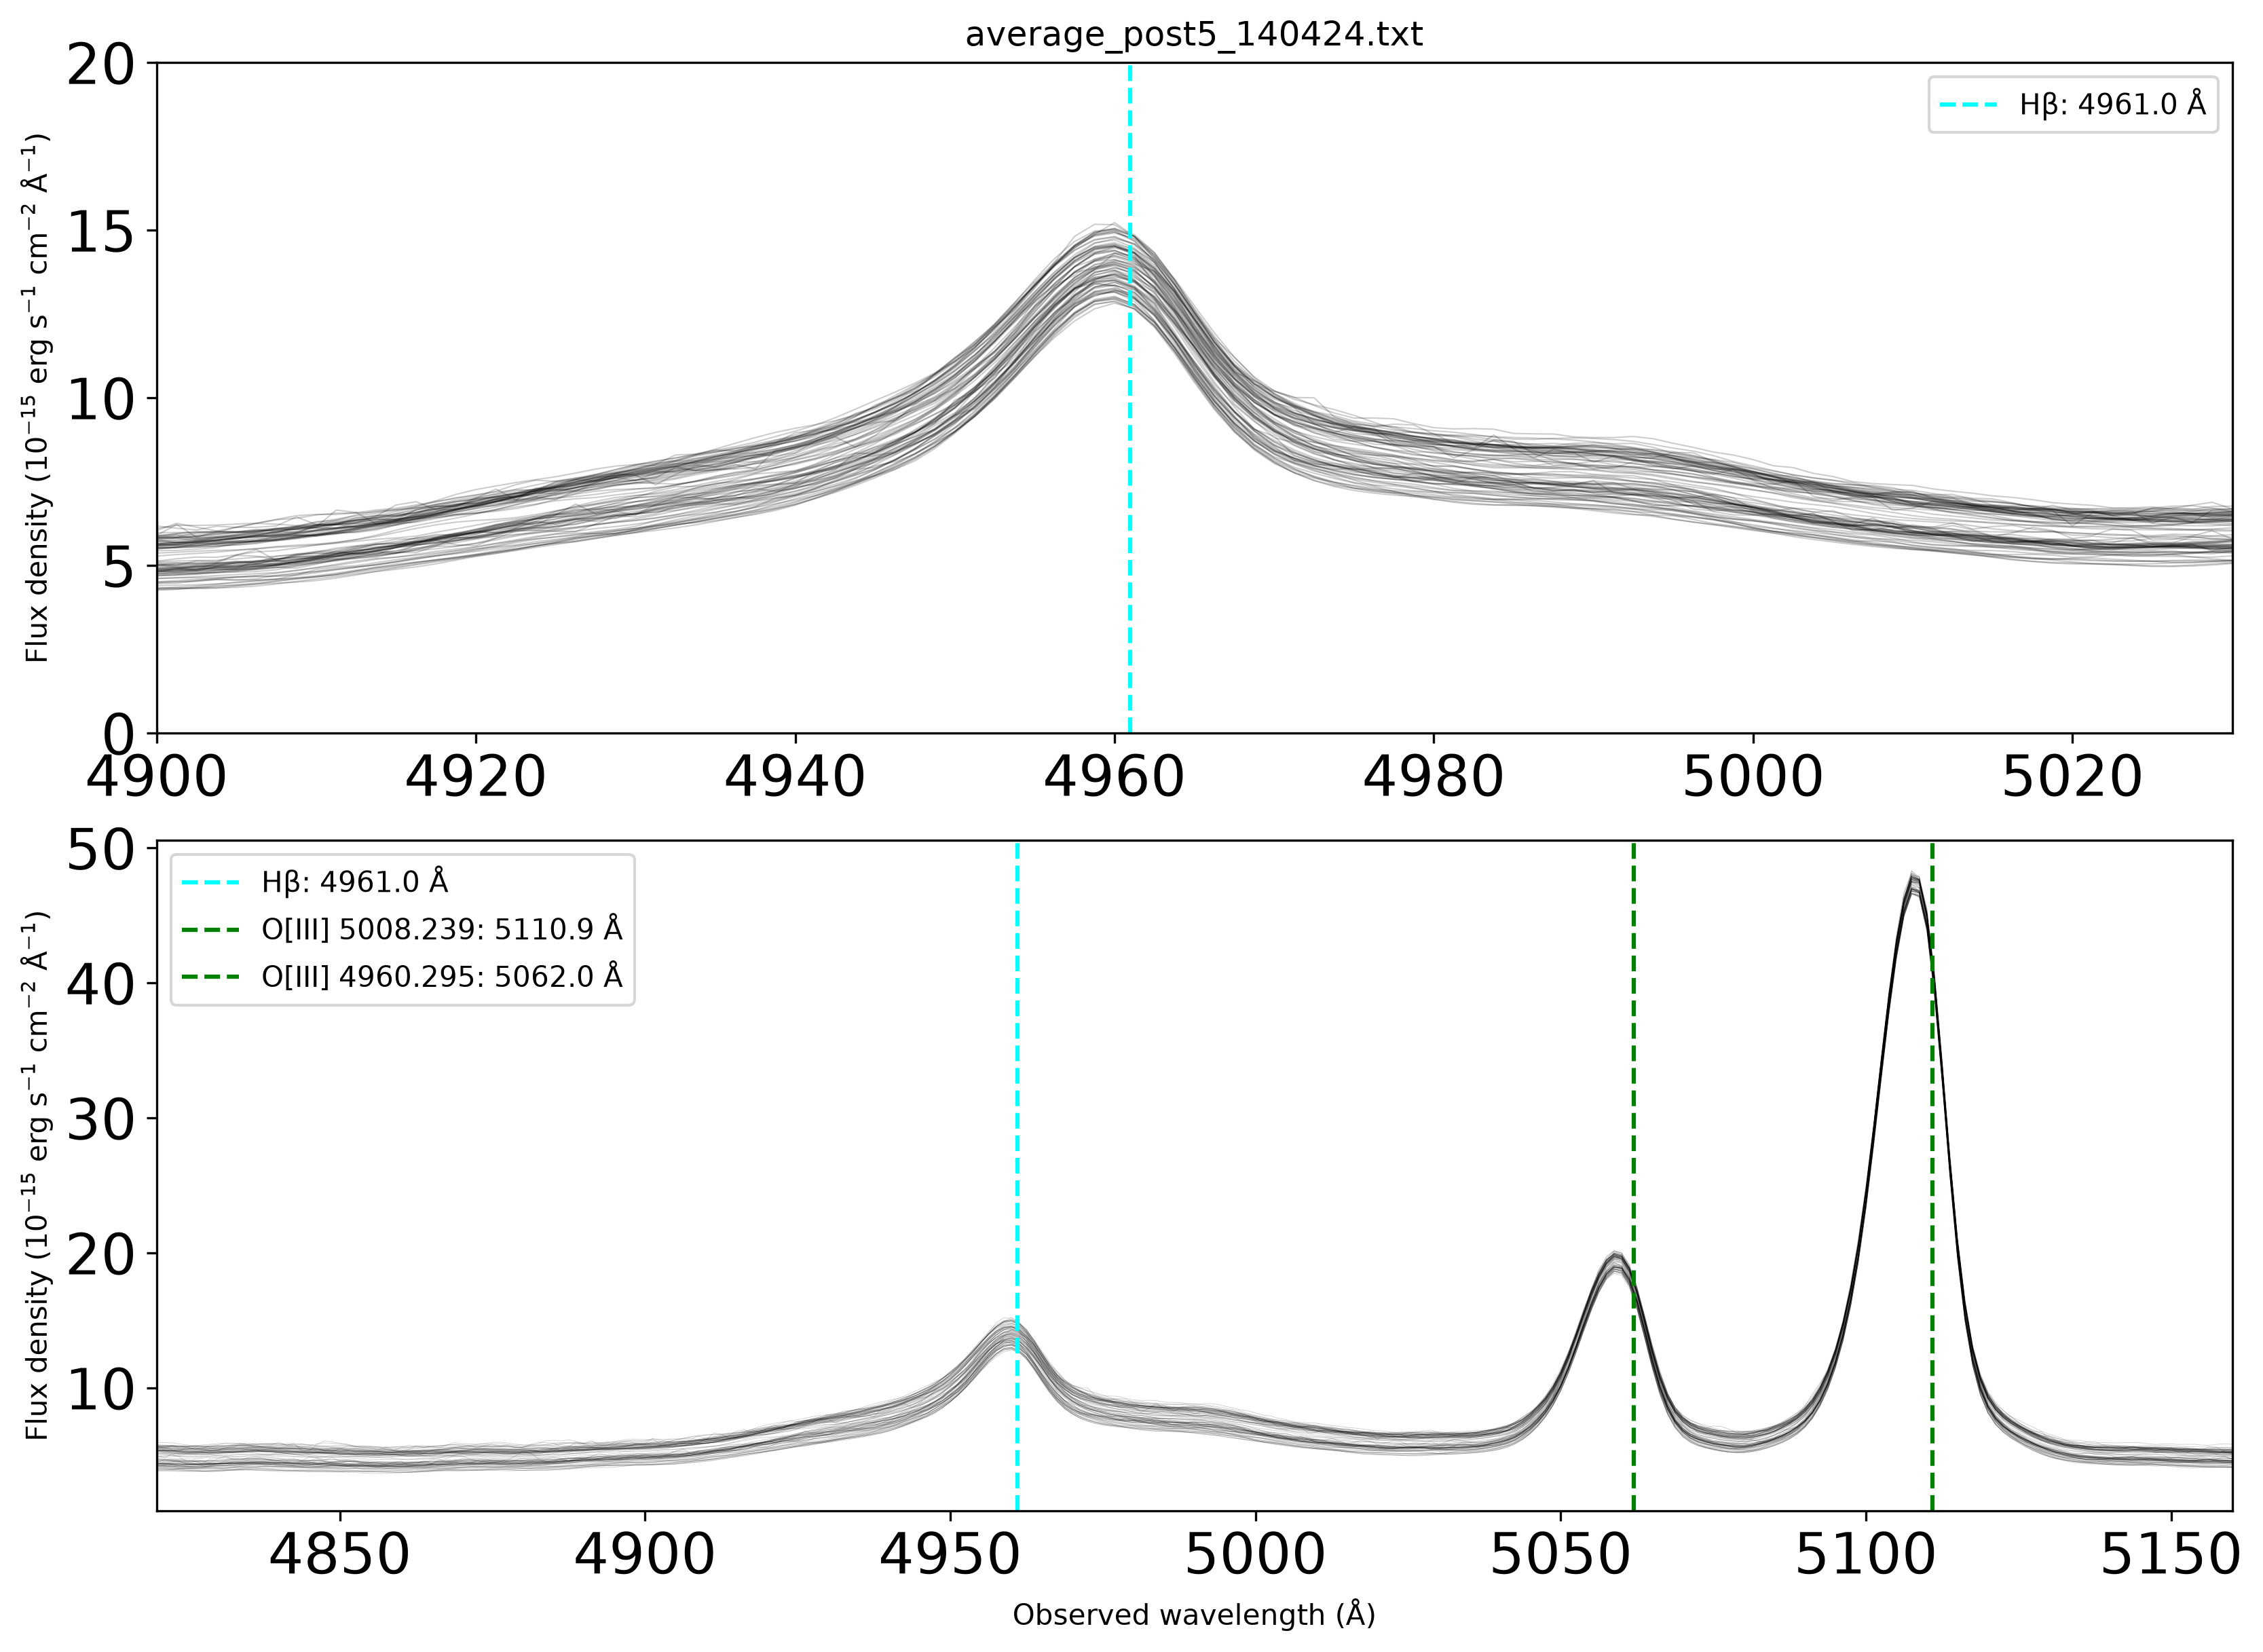

In [72]:
print(len(spectra_files))

fig, axes = plt.subplots(2, 1, figsize=(11, 8),dpi = 300, constrained_layout=True)
for i in range(len(spectra_files)):

    spectrum_file = spectra_files[i]
    spectrum = np.loadtxt(spectrum_file)
    
    wavelength = spectrum[:,0]
    flux = spectrum[:, 1]
    flux_error = spectrum[:,2]

    axes[0].plot(wavelength, flux * 1e15, color="black", linewidth=0.5, alpha = 0.2)
    axes[0].set_title(spectrum_file.name)
    axes[0].set_ylabel(r"Flux density ($10^{-15}$ erg s$^{-1}$ cm$^{-2}$ Å$^{-1}$)")
    axes[0].set_xlim(4900, 5030)
    axes[0].set_ylim(0, 20)


    axes[1].plot(wavelength, flux * 1e15, color="black", linewidth=0.2, alpha = 0.2)
    axes[1].set_xlim(4820, 5160)
    axes[1].set_xlabel("Observed wavelength (Å)")
    axes[1].set_ylabel(r"Flux density ($10^{-15}$ erg s$^{-1}$ cm$^{-2}$ Å$^{-1}$)")



lines = {"Hβ": 4861.33,
         "O[III] 5008.239": 5008.239,
         "O[III] 4960.295": 4960.295,}
line_colors = ["cyan", "green", "green"]

for index, (line,wavelength) in enumerate(lines.items()):
    observed_wavelength = wavelength*(1+z)
    axes[1].axvline(
            observed_wavelength, 
            linestyle="--", 
            c=line_colors[index],
            label=f"{line}: {observed_wavelength:.1f} Å" )
    axes[0].axvline(
            observed_wavelength, 
            linestyle="--", 
            c=line_colors[index],
            label=f"{line}: {observed_wavelength:.1f} Å" if line == "Hβ" else "_nolegend_")

axes[1].legend()
axes[0].legend()

plt.show()

# Fitting all Epochs

In [47]:
red_chis = {}  

for i in range(len(spectra_files)):

    spectrum_file = spectra_files[i]
    spectrum = np.loadtxt(spectrum_file)
    
    wavelength = spectrum[:,0]
    flux = spectrum[:, 1]
    flux_error = spectrum[:,2]
    
    q = QSOFit(
    wavelength,
    flux*1e17,
    flux_error*1e17,
    z,
    path=str(parameter_file.parent),)

    q.Fit(
    name = spectrum_file.name,
    param_file_name=parameter_file.name,
    nsmooth=1,
    reject_badpix=False,
    deredden=False,
    decompose_host=False,
    Fe_uv_op=True,
    poly=False,
    BC=False,
    linefit=True,
    MC=False,
    MCMC=False,
    save_result=False,
    plot_fig=False,
    save_fig=False,)

    fit_values = dict(zip(q.line_result_name, q.line_result))
    red_chis[spectrum_file.name] = float(fit_values["1_line_red_chi2"])


# Checking Fits

In [68]:
print("average red chi squared: ", np.mean(list(red_chis.values())))
print("Largest red chi squared: ", np.max(list(red_chis.values())))
print("Smallest red chi squared: ", np.min(list(red_chis.values())))


file = next(k for k, v in red_chis.items() if v == np.max(list(red_chis.values())))
print("Largest red chi squared file: ", file)


count = sum(1 for x in list(red_chis.values()) if x > 200)
print("epochs with red chi squared > 200 : ",count)


average red chi squared:  2047.7595968419291
Largest red chi squared:  24008.600281843905
Smallest red chi squared:  18.5563023216458
Largest red chi squared file:  average_post5_140217.txt
epochs with red chi squared > 200 :  76


# Fitting the Average

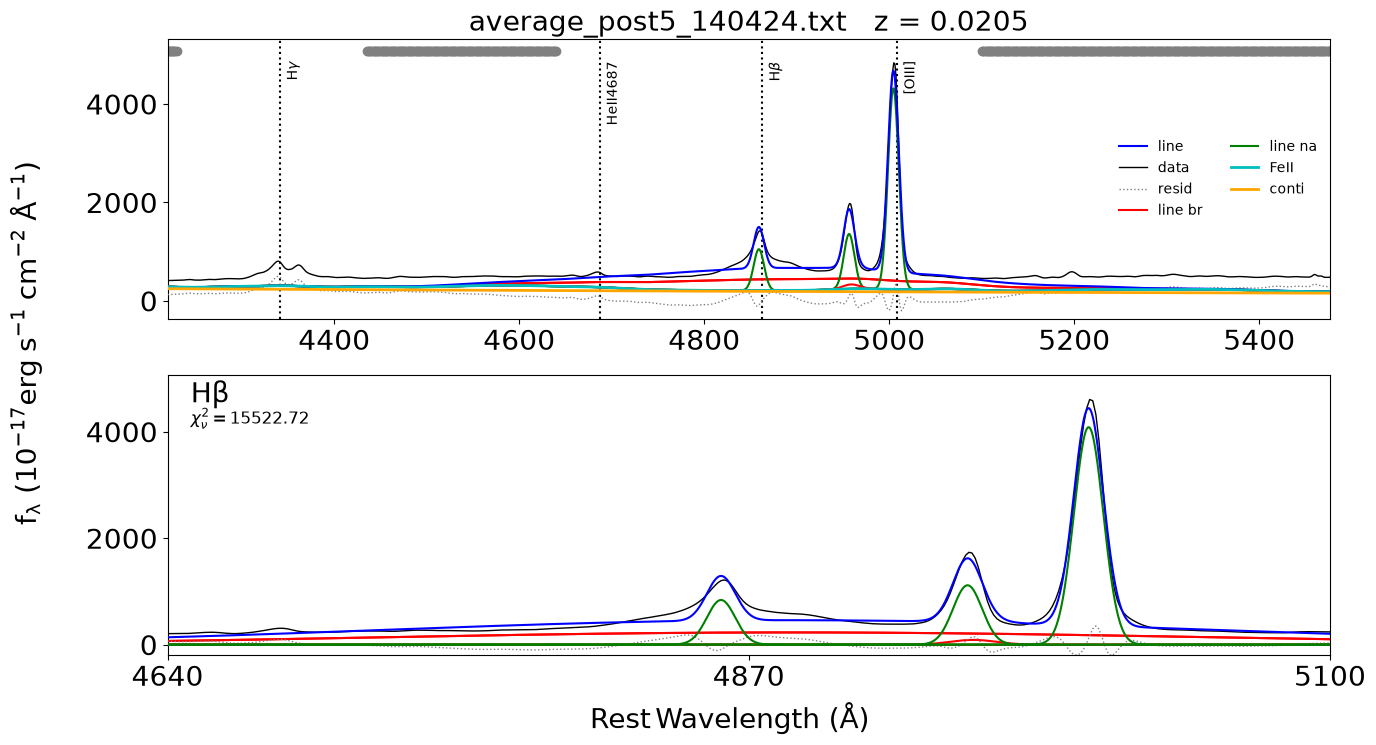

In [66]:
stack = np.stack([np.loadtxt(path) for path in spectra_files])

wavelength = stack[0, :, 0]
mean_flux = stack[:, :, 1].mean(axis=0)
mean_error = np.sqrt((stack[:, :, 2]**2).sum(axis=0)) / len(spectra_files)

q = QSOFit(
wavelength,
mean_flux*1e17,
mean_error*1e17,
z,
path=str(parameter_file.parent),)

q.Fit(
name = spectrum_file.name,
param_file_name=parameter_file.name,
nsmooth=1,
reject_badpix=False,
deredden=False,
decompose_host=False,
Fe_uv_op=True,
poly=False,
BC=False,
linefit=True,
MC=False,
MCMC=False,
save_result=False,
plot_fig=True,
save_fig=False,)